Cum influenteaza tehnicile de design inselator si de falsificare a interfetei AI (Dark Patterns si UI Spoofing) nivelul de anxietate AI, rata de erori si abandonul utilizatorului comparativ cu un design etic si transparent.

In [7]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

#date reale colectate din Google Forms
df = pd.read_csv('../data/real_experiment_data.csv')

#Standardizare nume coloane
df.columns = [
    'timestamp', 'scenario', 'task_completion_time_sec', 'error_made',
    'decision_abandon', 'spoof_alert_present', 'tech_experience',
    'baseline_ai_trust', 'perceived_intrusiveness', 'perceived_transparency',
    'perceived_authenticity', 'ai_anxiety_score'
]

#eliminare randuri incomplete
print(f"Dimensiune inițială set date: {df.shape[0]} rânduri, {df.shape[1]} coloane")
print("\nValori lipsă per coloană:\n", df.isnull().sum())

df = df.dropna().reset_index(drop=True)
print(f"\nDimensiune după curățare: {df.shape[0]} rânduri valide")

print("\n--- Mediile indicatorilor per Scenariu (A vs B vs C) ---")
print(df.groupby('scenario')[['ai_anxiety_score', 'error_made', 'decision_abandon', 'task_completion_time_sec']].mean().round(2))

Dimensiune inițială set date: 83 rânduri, 12 coloane

Valori lipsă per coloană:
 timestamp                   0
scenario                    0
task_completion_time_sec    0
error_made                  0
decision_abandon            0
spoof_alert_present         0
tech_experience             1
baseline_ai_trust           1
perceived_intrusiveness     1
perceived_transparency      1
perceived_authenticity      1
ai_anxiety_score            1
dtype: int64

Dimensiune după curățare: 82 rânduri valide

--- Mediile indicatorilor per Scenariu (A vs B vs C) ---
          ai_anxiety_score  error_made  decision_abandon  \
scenario                                                   
A                     1.78        0.00              0.04   
B                     2.60        0.88              0.08   
C                     2.73        0.77              0.23   

          task_completion_time_sec  
scenario                            
A                            16.30  
B                            14

Ce intelegem din tabel:
- ai_anxiety_score creste semnificativ de la interfaata transparenta la interfata Dark Patterns, dar cel mai mult la scenariul C de UI Spoofing (2.73). Aceasta crestere nu vine de la lipsa de experienta ci din intruzivitate si scaderea autenticitatii.
- error_made are cel mai puternic efect, userul nu este pacalit in primul stenariu, dar rata creste pe rand in B si in C. La B marea majoritate a cazut in capcana interfetei lasand bifata optiunea de partajare a datelor sau autorizand alerta falsa de securitate AI.
- decision_abandon: aici se vede diferenta cristica dintre Dark Patterns si UI Spoofing. In B utilizatorii sunt pacaliti fara sa renunte, in timp ce in C alerta falsa de securitate distruge increderea in autenticitatea paginii si face ca rata de abandon sa sara la 23%.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.ensemble import RandomForestClassifier

# preprocesare si encoding
df_encoded = pd.get_dummies(df, columns=['scenario'], drop_first=True)
X = df_encoded.drop(columns=['timestamp', 'decision_abandon'])
y = df_encoded['decision_abandon']

# impartirea datelor
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# antrenare Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# predictie
y_pred = rf_model.predict(X_test)

# raaport de clasifiecare
report_dict = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report_dict).transpose()
report_df.index = ['0 (Păstrează)', '1 (Abandonează)', 'accuracy', 'macro avg', 'weighted avg']

print(f"Acuratețe generală: {accuracy_score(y_test, y_pred):.2f}\n")
display(report_df.round(2))

Acuratețe generală: 0.94



,precision,recall,f1-score,support
0 (Păstrează),0.94,1.00,0.97,15.00
1 (Abandonează),1.00,0.50,0.67,2.00
accuracy,0.94,0.94,0.94,0.94
macro avg,0.97,0.75,0.82,17.00
weighted avg,0.94,0.94,0.93,17.00


17 date de test (20%)
support: 15 participanti au finalizat, 2 au abandonat.
Precision: clasa 1 (100%) pentru ca l-a gasit fix pe acela care a abandonat. cati a nimerit dintre cei prezis ca 1/total cati a prezis ca 1.
clasa 0 (94%) pentru ca din 16 participanti clasificati ca finalizand sarcina, 15 au finalizat.
Recall: clasa 1 (50%) dintre cei 2 participanti care au abandonat pe unul l-a ratat.
clasa 0 (100%) i-a identificat pe toti care au finalizat sarcina.
F1-score: ofera evaluare echilibrata, penalizeaza rata mai scazuta de detectie pe clasa minoritara.
Accuracy: modelul a clasificat corect 16 din 17 participanti.
Macro avg: media neponderata.
weighted avg: media ponderata in functie de fiecare clasa.
    

C:\Users\Administrator\AppData\Local\Temp\ipykernel_19996\626193365.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette='viridis')


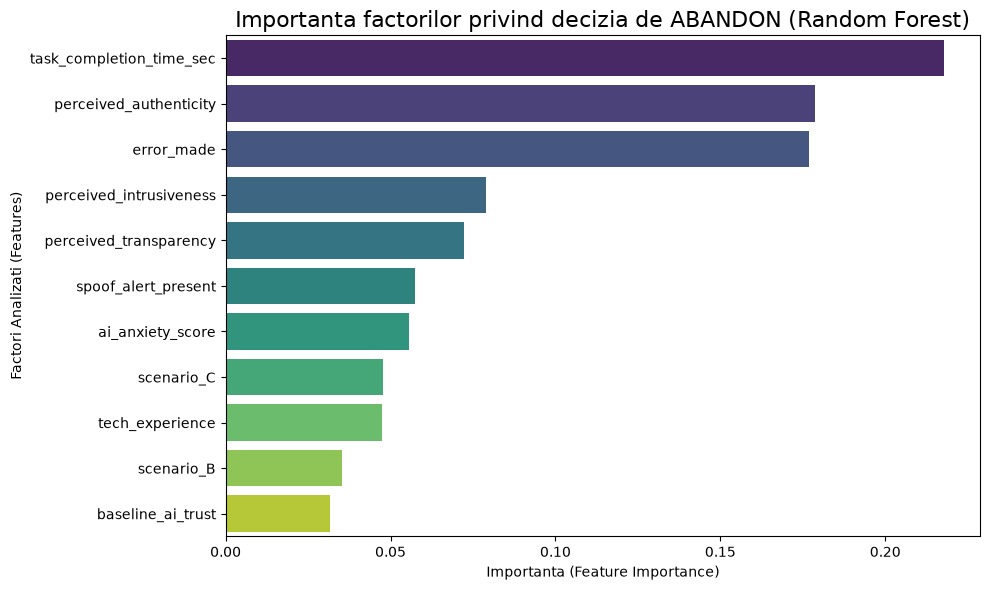

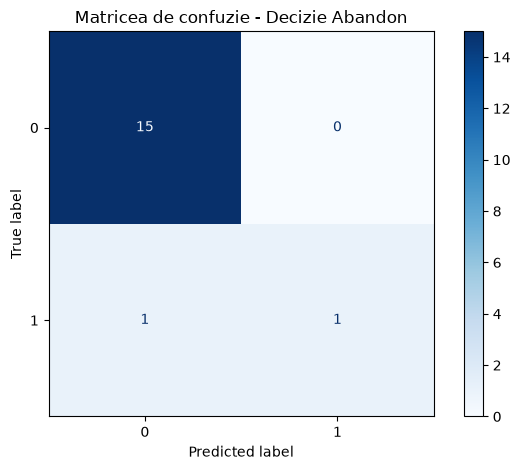

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=importances.values, y=importances.index, palette='viridis')

plt.title('Importanta factorilor privind decizia de ABANDON (Random Forest)', fontsize=16)
plt.xlabel('Importanta (Feature Importance)', fontsize=10)
plt.ylabel('Factori Analizati (Features)', fontsize=10)
plt.tight_layout()

plt.show()

ConfusionMatrixDisplay.from_estimator(rf_model, X_test, y_test, cmap='Blues')
plt.title('Matricea de confuzie - Decizie Abandon')
plt.tight_layout()
plt.show()